# Amplify QC — how the model works

This notebook walks through the model behind Amplify QC, from raw fluorescence to the highlighted regions you see in the app.
It runs against the **real pretrained model** (`qpcr_model.pkl`), so every number here is what the app shows.

**The two questions the product answers, with two independent models**

| Question | Model | Output |
|---|---|---|
| *Did this well amplify?* | RandomForest on curve-shape features | `AMP` / `NO AMP` + confidence |
| *Does the curve carry an artifact, and where?* | 3-channel convolutional autoencoder, scored **per cycle** and **per window** | review tier + the flagged cycles |

This notebook focuses on the second one, because that is where the highlighting comes from.

**Contents**
1. Load the model and a plate
2. The three input channels (raw, 1st and 2nd derivative)
3. The autoencoder architecture, and why replicate padding
4. Training
5. Calibration: what "normal" looks like, per cycle and per window
6. Inference step by step for one well (per-cycle error → per-window error → worst unit)
7. How the highlighted region and red circles are chosen
8. Whole-plate inference and the review tiers
9. Why the review limit is 1.5×

In [1]:
import inspect, sys, warnings
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

import qpcr_v2
from qpcr_v2 import (QPCRPipelineV2, QPCRAnomalyV2, ConvAE3, ChannelScaler, build_channels,
                     make_windows, REVIEW_MULT, HIGH_MULT)
from qpcr_pipeline import CYCLE_COLS, N_CYCLES

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 10})
BLUE, RED, AMBER, GREY = "#2563EB", "#C62828", "#F59E0B", "#94A3B8"

## 1. Load the model and a plate

In [2]:
pipe = torch.load("qpcr_model.pkl", weights_only=False)     # RandomForest + autoencoder + thresholds
ae   = pipe.ae                                              # the QPCRAnomalyV2 object (the quality model)
plate = pd.read_csv("demo_plate.csv")                       # 96 wells, 40 cycles each (c1..c40)

print("trained:", pipe.meta["trained_at"], "| real curves:", pipe.meta["n_real_wells"],
      "| curves incl. augmentation:", pipe.meta["n_ae_curves"])
print("plate:", plate.shape, "-> columns well, row, col, c1..c40 (+ optional ground truth)")
plate[["well", "row", "col", "c1", "c20", "c40"]].head()

trained: 2026-11-08 21:02 | real curves: 1671 | curves incl. augmentation: 3762
plate: (96, 49) -> columns well, row, col, c1..c40 (+ optional ground truth)


,well,row,col,c1,c20,c40
0,A1,A,1,0.023400,0.149244,0.034776
1,A2,A,2,0.016746,0.108216,2.628747
2,A3,A,3,0.020094,0.021612,0.023783
3,A4,A,4,0.008059,3.213640,3.374293
4,A5,A,5,0.016434,0.023464,3.875144


A qPCR curve is 40 fluorescence readings (one per cycle). Negatives stay flat near 0.02 RFU; positives climb in a
sigmoid (baseline → exponential takeoff → plateau). Here are one of each from the plate:

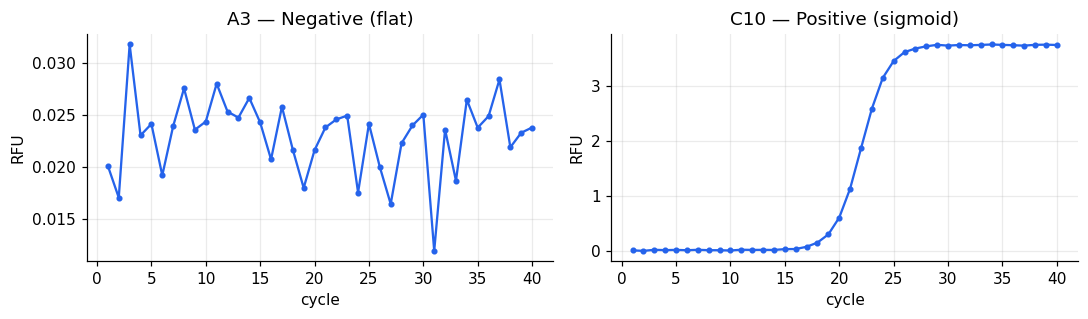

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
for a, well, title in zip(ax, ["A3", "C10"], ["Negative (flat)", "Positive (sigmoid)"]):
    y = plate.loc[plate.well == well, CYCLE_COLS].to_numpy()[0]
    a.plot(range(1, 41), y, "-o", ms=3, color=BLUE); a.set_title(f"{well} — {title}")
    a.set_xlabel("cycle"); a.set_ylabel("RFU")
plt.tight_layout(); plt.show()

## 2. The three input channels

A spike or a drift is easier to see in the **slope** of a curve than in its raw value, so the model reads three channels per well:

| Channel | Meaning | Why |
|---|---|---|
| `raw` | fluorescence (RFU) | the signal itself |
| `d1` | 1st derivative (slope per cycle) | takeoff speed; sudden jumps |
| `d2` | 2nd derivative (curvature) | kinks and spikes stand out |

The derivative channels exist on **negative curves too** (they are just near-zero noise), so the model learns what a *normal flat* trace looks like.
Derivatives come from a 3-point smoothed curve, padded by edge replication so the first and last cycles are not dragged toward zero.

In [4]:
print(inspect.getsource(build_channels))

def build_channels(X):
    """(n, 40) raw RFU -> (n, 3, 40): raw, d1, d2. Derivatives come from a 3-pt
    smoothed curve padded by edge replication, so the smoother does not drag
    the first/last cycles toward zero."""
    X = np.asarray(X, dtype=np.float64)
    pad = np.pad(X, ((0, 0), (1, 1)), mode="edge")
    smoothed = (pad[:, :-2] + pad[:, 1:-1] + pad[:, 2:]) / 3
    d1 = np.gradient(smoothed, axis=1)
    d2 = np.gradient(d1, axis=1)
    return np.stack([X, d1, d2], axis=1)



channels array: (96, 3, 40)


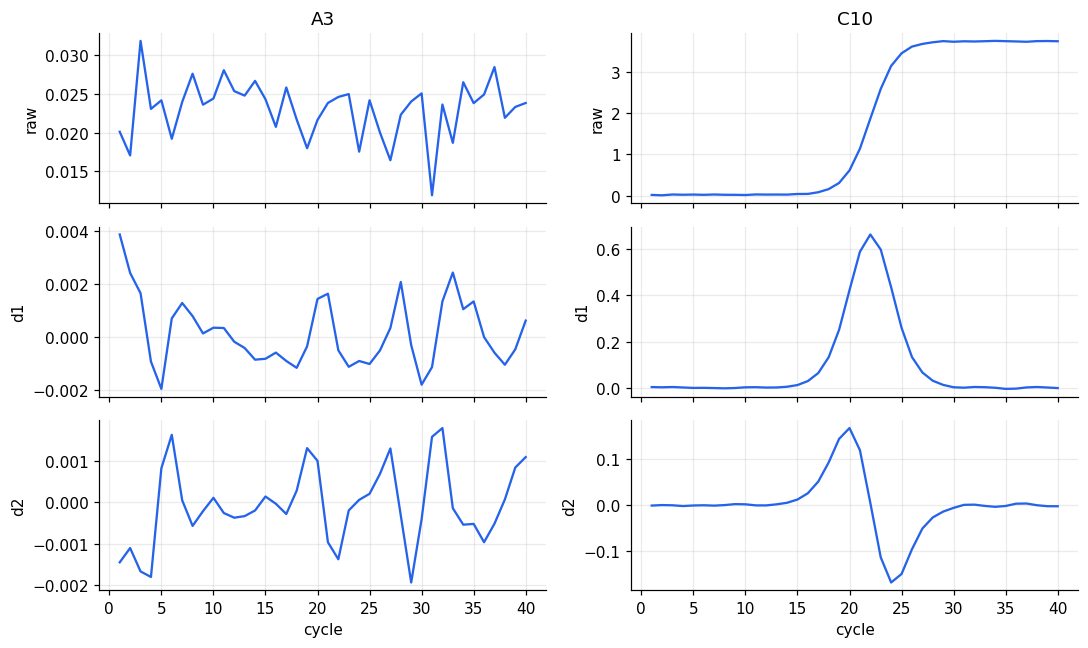

In [5]:
ch = build_channels(plate[CYCLE_COLS].to_numpy())           # (wells, 3 channels, 40 cycles)
print("channels array:", ch.shape)

fig, axes = plt.subplots(3, 2, figsize=(10, 6), sharex=True)
for col, well in enumerate(["A3", "C10"]):
    i = plate.index[plate.well == well][0]
    for row, name in enumerate(["raw", "d1", "d2"]):
        axes[row, col].plot(range(1, 41), ch[i, row], color=BLUE)
        axes[row, col].set_ylabel(name)
    axes[0, col].set_title(well)
axes[2, 0].set_xlabel("cycle"); axes[2, 1].set_xlabel("cycle")
plt.tight_layout(); plt.show()

**Putting the channels on one scale.** Raw RFU (0.02 → 4) and its derivatives (≈0.005 → 0.5) differ by orders of magnitude, and a flat
negative must stay as visible to the model as a 4 RFU positive. Each channel is divided by 3× its own baseline noise and passed through
`arcsinh`: almost linear near zero (noise stays visible), logarithmic for big values (positives don't swamp negatives).

In [6]:
print(inspect.getsource(ChannelScaler))

class ChannelScaler:
    """asinh(channel / s_k), with s_k = 3 x the within-curve noise sd of channel k
    over the baseline cycles of the training curves. Linear near zero (noise
    stays visible), logarithmic for large values (positives don't swamp negatives)."""

    def fit(self, channels):
        base = channels[:, :, BASELINE]
        noise = (base - base.mean(axis=2, keepdims=True)).std(axis=(0, 2))
        self.s = 3.0 * noise + 1e-9
        return self

    def transform(self, channels):
        return np.arcsinh(channels / self.s[None, :, None])

    def inverse(self, scaled):
        return np.sinh(scaled) * self.s[None, :, None]



In [7]:
print("per-channel scale s_k (3 x baseline noise):", dict(zip(["raw", "d1", "d2"], [round(float(v), 5) for v in ae.scaler.s])))
x_scaled = ae.scaler.transform(ch)
print("scaled range per channel:", x_scaled.min(axis=(0, 2)).round(1), "to", x_scaled.max(axis=(0, 2)).round(1))

per-channel scale s_k (3 x baseline noise): {'raw': 0.01582, 'd1': 0.00574, 'd2': 0.00412}
scaled range per channel: [-2.7 -3.2 -4.7] to [6.5 5.7 4.7]


## 3. The autoencoder

An autoencoder is trained to **reconstruct normal curves**. Because it has only seen clean traces, it reconstructs clean traces well
and artifacts badly. *The size of the reconstruction error, cycle by cycle, is the anomaly signal.*

Design choices that respect qPCR physics:

* **Kernel sizes 7 then 5.** A 7-cycle window spans the exponential takeoff, so the first layer sees takeoff as a shape, not as noise.
* **Replicate padding on every convolution.** At cycle 1 or cycle 40 a convolution needs neighbours that don't exist. Zero padding would invent
  a cliff between 0.02 RFU and 0 (or 4 RFU and 0); replicate padding copies the end value outward, i.e. "the baseline/plateau continues".
* **Upsample + conv decoder** (not `ConvTranspose`), which has its own edge artifacts.
* **Small 6-number bottleneck.** The network cannot memorise a curve; it must keep only the essential shape.

In [8]:
print(inspect.getsource(ConvAE3))

class ConvAE3(nn.Module):
    """3-channel conv AE over the cycle axis. padding_mode='replicate' is the
    physics-respecting default; 'zeros' exists only to demonstrate the edge bias."""

    def __init__(self, latent_dim=6, padding_mode="replicate", n_cycles=N_CYCLES):
        super().__init__()
        m = padding_mode
        self.len_b = n_cycles // 4  # two stride-2 stages
        self.encoder = nn.Sequential(
            _conv(3, 16, 7, 1, m), nn.ReLU(),     # takeoff-scale receptive field
            _conv(16, 32, 5, 2, m), nn.ReLU(),
            _conv(32, 32, 5, 2, m), nn.ReLU(),
            nn.Flatten(),
            nn.Linear(32 * self.len_b, latent_dim),
        )
        self.dec_fc = nn.Sequential(nn.Linear(latent_dim, 32 * self.len_b), nn.ReLU())
        self.decoder = nn.Sequential(
            nn.Upsample(scale_factor=2, mode="linear", align_corners=False),
            _conv(32, 32, 5, 1, m), nn.ReLU(),
            nn.Upsample(scale_factor=2, mode="linear", align_corne

In [9]:
model = ae.ae
print("parameters:", sum(p.numel() for p in model.parameters()))
x = torch.tensor(x_scaled[:2], dtype=torch.float32)
print("input     :", tuple(x.shape), " (wells, channels, cycles)")
h = x
for layer in model.encoder:
    h = layer(h); print(f"  {layer.__class__.__name__:<8} -> {tuple(h.shape)}")
print("bottleneck:", tuple(h.shape), " <- 6 numbers describe the whole curve")
print("output    :", tuple(model(x).shape), " (same shape as input)")

parameters: 20329
input     : (2, 3, 40)  (wells, channels, cycles)
  Conv1d   -> (2, 16, 40)
  ReLU     -> (2, 16, 40)
  Conv1d   -> (2, 32, 20)
  ReLU     -> (2, 32, 20)
  Conv1d   -> (2, 32, 10)
  ReLU     -> (2, 32, 10)
  Flatten  -> (2, 320)
  Linear   -> (2, 6)
bottleneck: (2, 6)  <- 6 numbers describe the whole curve
output    : (2, 3, 40)  (same shape as input)


**What replicate padding does at the edge** (a one-line demo with a flat baseline of 0.02):

In [10]:
edge = torch.full((1, 1, 6), 0.02)
for mode in ["zeros", "replicate"]:
    padded = torch.nn.functional.pad(edge, (2, 2), mode="constant" if mode == "zeros" else "replicate")
    print(f"{mode:<10}", padded.numpy().round(3).ravel())

zeros      [0.   0.   0.02 0.02 0.02 0.02 0.02 0.02 0.   0.  ]
replicate  [0.02 0.02 0.02 0.02 0.02 0.02 0.02 0.02 0.02 0.02]


## 4. Training

`train_model.py` trains once and saves `qpcr_model.pkl`; the app only runs inference.

* The autoencoder trains on **clean curves only** (1,254 real + 2 synthetic copies each = 3,762), minimising mean-squared error across all three channels.
* Synthetic copies: negatives get their cycles shuffled (their noise is i.i.d.), positives are shifted a few cycles earlier/later and slightly rescaled.
  This improved reconstruction error on unseen clean curves by ~19%.
* 25% of the real clean wells are **held out for calibration** (next section) and never trained on.

In [11]:
print(inspect.getsource(QPCRPipelineV2.fit))

    def fit(self, train_df, verbose=True):
        """train_df: clean curves with true_label (Positive/Negative_Clean)."""
        y = make_amp_labels(train_df)
        rng = np.random.default_rng(self.random_state)
        calib_idx = np.concatenate([
            rng.choice(np.where(y == c)[0], int(self.calib_frac * (y == c).sum()), replace=False)
            for c in (0, 1)])
        mask = np.zeros(len(train_df), bool)
        mask[calib_idx] = True
        fit_df, calib_df = train_df[~mask].reset_index(drop=True), train_df[mask].reset_index(drop=True)

        if verbose:
            print(f"Training classifier on {len(fit_df)} wells...")
        self.feature_names = list(curve_features(fit_df).columns)
        self.clf = RandomForestClassifier(n_estimators=300, max_depth=8, class_weight="balanced",
                                          random_state=self.random_state)
        self.clf.fit(curve_features(fit_df).to_numpy(), make_amp_labels(fit_df))

        if verbose:
         

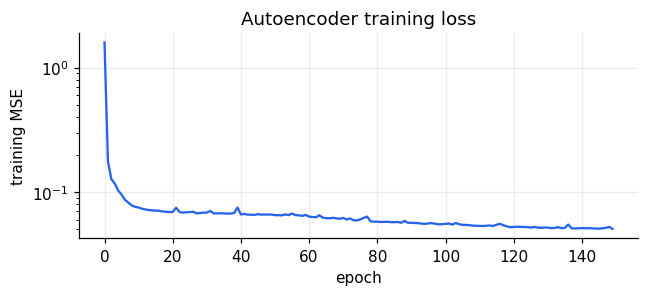

final loss: 0.0506 (noise puts a floor under this: noise cannot be reconstructed)


In [12]:
plt.figure(figsize=(6, 2.8)); plt.plot(ae.losses, color=BLUE)
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("training MSE"); plt.title("Autoencoder training loss")
plt.tight_layout(); plt.show()
print("final loss:", round(ae.losses[-1], 4), "(noise puts a floor under this: noise cannot be reconstructed)")

## 5. Calibration — what "normal" looks like

A raw error number means nothing on its own, so we measure what errors look like on **held-out clean wells** and judge new wells against that.
Everything is kept **per class** (negatives and positives have very different error sizes) and **per cycle** and **per window**:

1. **Residual sd** per class, channel and cycle → turns a residual into a z-score so every channel and cycle counts equally.
2. **Per-cycle threshold**: the 99th percentile of the (z-scored) cycle error on clean wells, for each cycle.
3. **Per-window threshold**: the same for each window.
4. **Flag cut**: the 95th percentile of each clean well's *worst* unit ratio (explained below).

In [13]:
windows = ae.windows
print(len(windows), "windows (name, first cycle, last cycle). First 3 and the phase zones:")
for w in windows[:3] + windows[-5:]: print("  ", w)

74 windows (name, first cycle, last cycle). First 3 and the phase zones:
   ('w5: 1-5', 1, 5)
   ('w5: 2-6', 2, 6)
   ('w5: 3-7', 3, 7)
   ('baseline 1-5', 1, 5)
   ('early 3-15', 3, 15)
   ('takeoff 10-25', 10, 25)
   ('mid 15-30', 15, 30)
   ('plateau 30-40', 30, 40)


In [14]:
print(inspect.getsource(make_windows))

def make_windows(n_cycles=N_CYCLES, widths=SLIDING_WIDTHS, zones=PHASE_ZONES):
    """List of (name, start, end), 1-indexed inclusive. Multi-scale sliding
    windows at stride 1, then the fixed phase zones."""
    wins = []
    for w in widths:
        for s in range(1, n_cycles - w + 2):
            wins.append((f"w{w}: {s}-{s + w - 1}", s, s + w - 1))
    return wins + list(zones)



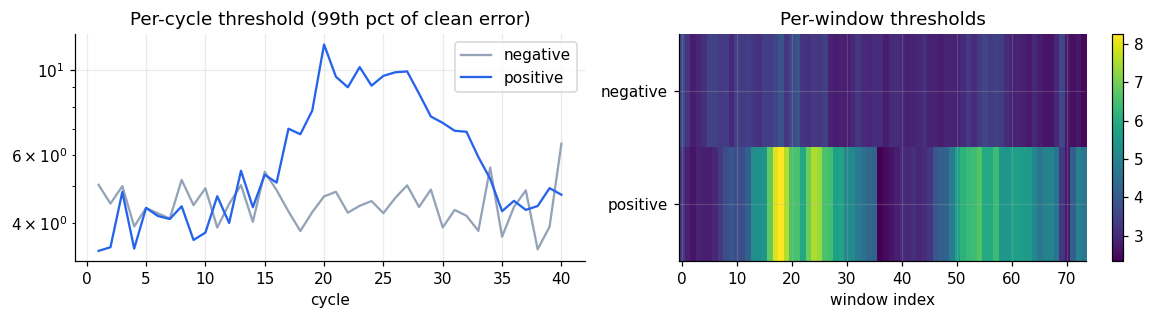

calibration wells per class (neg, pos): {0: 226, 1: 191}
flag cut (95th pct of the worst-unit ratio on clean wells): 1.482
review limit = 1.5 x flag cut = 2.223


In [15]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
for c, (label, color) in enumerate([("negative", GREY), ("positive", BLUE)]):
    ax[0].plot(range(1, 41), ae.thr_cycle[c], color=color, label=label)
ax[0].set_title("Per-cycle threshold (99th pct of clean error)"); ax[0].set_xlabel("cycle"); ax[0].set_yscale("log"); ax[0].legend()
im = ax[1].imshow(ae.thr_win, aspect="auto", cmap="viridis")
ax[1].set_yticks([0, 1]); ax[1].set_yticklabels(["negative", "positive"]); ax[1].set_xlabel("window index"); ax[1].set_title("Per-window thresholds")
plt.colorbar(im, ax=ax[1]); plt.tight_layout(); plt.show()
print("calibration wells per class (neg, pos):", ae.class_counts)
print("flag cut (95th pct of the worst-unit ratio on clean wells):", round(ae.flag_cut, 3))
print(f"review limit = {REVIEW_MULT} x flag cut =", round(ae.flag_cut * REVIEW_MULT, 3))

## 6. Inference step by step, for one well

We now reproduce **by hand** what `score()` does, for well **A1** (a negative curve with a 3-cycle bump injected at cycles 19–21), then check it matches.

1. Build and scale the 3 channels.
2. Run the autoencoder → reconstruction.
3. Residual = reconstruction − input, for each channel and cycle.
4. Divide by the clean residual sd (per class) and square → **z² per channel per cycle**.
5. Average over the 3 channels → **error per cycle**.
6. Average the per-cycle errors inside each window → **error per window**.
7. Divide each by its own threshold → **ratios**. 1.0 means "as bad as the worst 1% of clean wells at that spot".
8. **S** = the largest ratio over all cycles and windows, and *where* it occurred.

In [16]:
well = "A1"
i = plate.index[plate.well == well][0]
row = plate.iloc[[i]]

# 1-2. channels -> scaled -> autoencoder
xs = ae._prep(row)                       # (1, 3, 40) scaled channels
z, rec = ae._run(xs)                     # latent (1, 6) and reconstruction (1, 3, 40)
# 3. residual
res = rec - xs
# class (0 = negative, 1 = positive) comes from the amplification classifier
cls = ae._cls(row)
print("class used for thresholds:", "positive" if cls[0] else "negative")

class used for thresholds: negative


In [17]:
# 4. z-score with the clean residual sd for this class, then square
z2 = (res / ae.res_sd[cls]) ** 2          # (1, 3, 40): z^2 per channel per cycle
# 5. average over the three channels -> one error per cycle
cycle_err = z2.mean(axis=1)               # (1, 40)
print("per-cycle error, cycles 15-23:", cycle_err[0, 14:23].round(1))

per-cycle error, cycles 15-23: [ 0.5 12.2 48.2 62.  97.6 65.1 92.3 55.7 42.1]


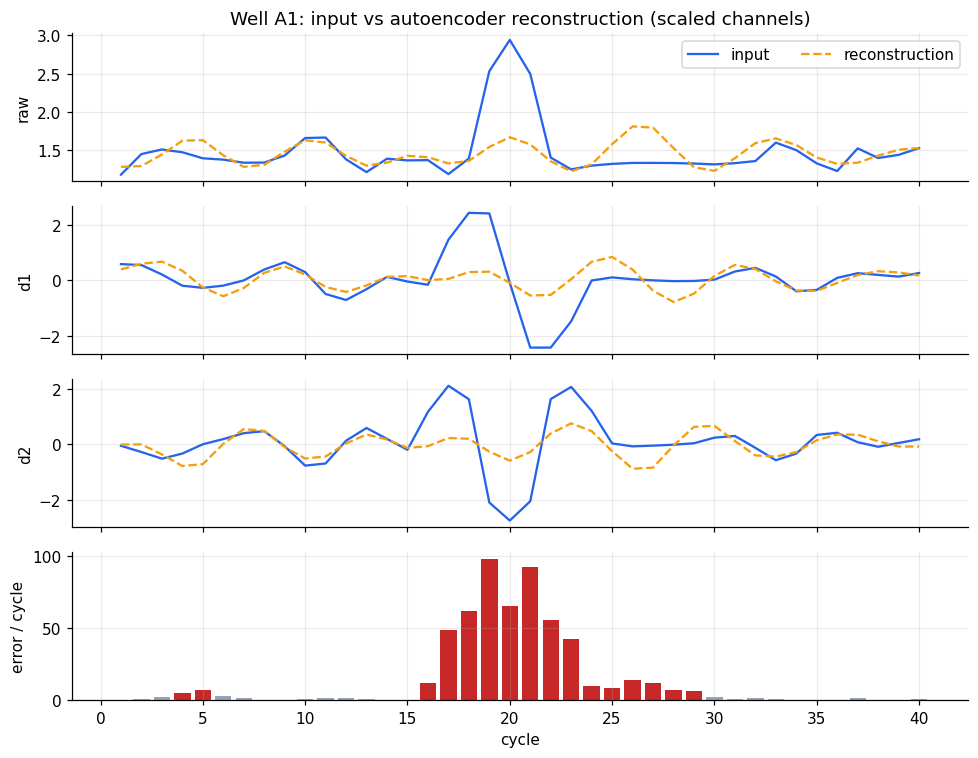

In [18]:
fig, ax = plt.subplots(4, 1, figsize=(9, 7), sharex=True)
cyc = np.arange(1, 41)
for k, name in enumerate(["raw", "d1", "d2"]):
    ax[k].plot(cyc, xs[0, k], color=BLUE, label="input"); ax[k].plot(cyc, rec[0, k], "--", color=AMBER, label="reconstruction")
    ax[k].set_ylabel(name)
ax[0].legend(ncol=2, loc="upper right"); ax[0].set_title(f"Well {well}: input vs autoencoder reconstruction (scaled channels)")
ax[3].bar(cyc, cycle_err[0], color=np.where(cycle_err[0] > ae.thr_cycle[cls][0], RED, GREY))
ax[3].set_ylabel("error / cycle"); ax[3].set_xlabel("cycle")
plt.tight_layout(); plt.show()

The autoencoder cannot reproduce the bump (the dashed reconstruction stays flat), so the residual — and therefore the error — is large exactly there.

**Per-window error.** Each window is just the mean of the per-cycle errors it covers. Windows catch *stretches* of mildly elevated error
that no single cycle would reveal (drifts, noise bursts).

In [19]:
def window_errors(cycle_err, windows):
    return np.stack([cycle_err[:, a - 1:b].mean(axis=1) for _, a, b in windows], axis=1)

win_err = window_errors(cycle_err, windows)
print("window errors:", win_err.shape, "(wells x windows)")
for (name, a, b), e in list(zip(windows, win_err[0]))[12:18]:
    print(f"  {name:<14} covers cycles {a}-{b}:  mean error = {e:.1f}")

window errors: (1, 74) (wells x windows)
  w5: 13-17      covers cycles 13-17:  mean error = 12.4
  w5: 14-18      covers cycles 14-18:  mean error = 24.6
  w5: 15-19      covers cycles 15-19:  mean error = 44.1
  w5: 16-20      covers cycles 16-20:  mean error = 57.0
  w5: 17-21      covers cycles 17-21:  mean error = 73.0
  w5: 18-22      covers cycles 18-22:  mean error = 74.5


**Ratios and the worst unit.** Every cycle error and window error is divided by its own clean-data threshold; `S` is the biggest ratio.

In [20]:
cycle_ratio = cycle_err / ae.thr_cycle[cls]           # (1, 40)
win_ratio   = win_err   / ae.thr_win[cls]             # (1, n_windows)
all_ratio   = np.concatenate([cycle_ratio, win_ratio], axis=1)
unit_names  = [f"cycle {c}" for c in range(1, 41)] + [w[0] for w in windows]

S   = all_ratio.max()
arg = all_ratio.argmax()
print(f"S = {S:.1f}  (worst unit: {unit_names[arg]})")
print(f"flag cut = {ae.flag_cut:.2f}, review limit = {ae.flag_cut * REVIEW_MULT:.2f}  ->",
      "FLAGGED" if S > ae.flag_cut * REVIEW_MULT else "not flagged")

S = 22.9  (worst unit: cycle 19)
flag cut = 1.48, review limit = 2.22  -> FLAGGED


A heatmap of every window's ratio makes the localisation visible (a cell is drawn only where the window covers that cycle):

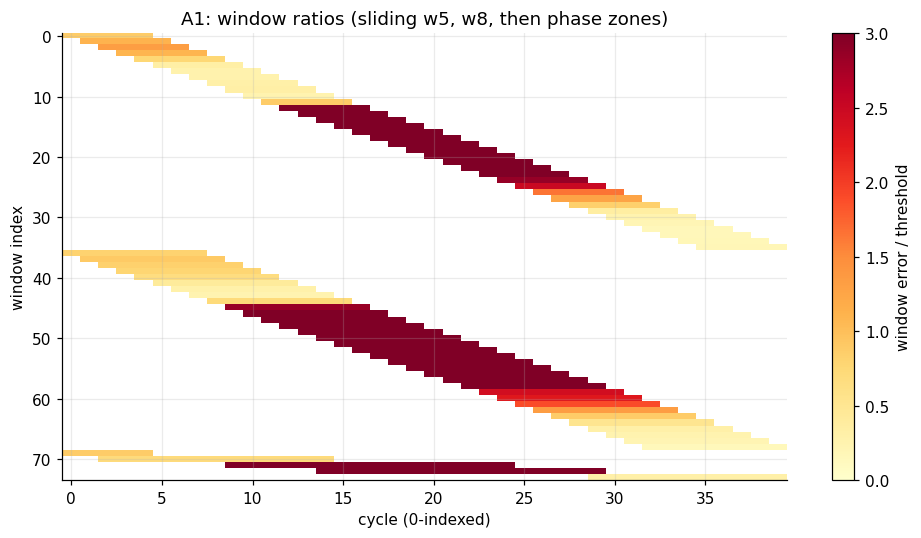

In [21]:
H = np.full((len(windows), 40), np.nan)
for k, (_, a, b) in enumerate(windows): H[k, a - 1:b] = win_ratio[0, k]
plt.figure(figsize=(9, 5)); plt.imshow(H, aspect="auto", cmap="YlOrRd", vmin=0, vmax=3, interpolation="nearest")
plt.colorbar(label="window error / threshold"); plt.xlabel("cycle (0-indexed)"); plt.ylabel("window index")
plt.title(f"{well}: window ratios (sliding w5, w8, then phase zones)"); plt.tight_layout(); plt.show()

**Check:** the hand-built numbers match the library's `score()` exactly.

In [22]:
sc = ae.score(row)
assert np.allclose(sc["cycle_ratio"], cycle_ratio, rtol=1e-4), "per-cycle ratios differ"
assert np.allclose(sc["win_ratio"], win_ratio, rtol=1e-4), "per-window ratios differ"
assert np.isclose(sc["S"][0], S, rtol=1e-4) and sc["S_label"][0] == unit_names[arg]
print("OK — manual inference == QPCRAnomalyV2.score()   (S =", round(float(sc['S'][0]), 2), ",", sc["S_label"][0], ")")

OK — manual inference == QPCRAnomalyV2.score()   (S = 22.89 , cycle 19 )


## 7. How the highlighted region and red circles are chosen

The app turns the ratios into what a reviewer sees:

1. **Is the well flagged?** `S` is above the review limit (`REVIEW_MULT` × flag cut).
2. **Worst span** — the cycle range of the worst unit (one cycle, or the window's range).
3. **Unusual cycles (red circles)** — cycles whose own ratio is above 1.0 and that sit within 3 cycles of the worst span.
4. **Flagged region (shaded band)** — from the first to the last unusual cycle, always including the worst span.

Only flagged wells get a band and circles, so a well that is merely noisy is never highlighted.

In [23]:
def flagged_region(cycle_ratio_row, span, is_flagged):
    """Return (unusual_cycles, region_start, region_end). Mirrors the logic in the app's curve view."""
    s0, s1 = span
    if not is_flagged:
        return np.array([], dtype=int), None, None
    cycles = np.arange(1, 41)
    hot = cycles[(cycle_ratio_row > 1.0) & (cycles >= s0 - 3) & (cycles <= s1 + 3)]
    r0 = min([s0] + list(hot)); r1 = max([s1] + list(hot))
    return hot, int(r0), int(r1)

print(inspect.getsource(flagged_region))

def flagged_region(cycle_ratio_row, span, is_flagged):
    """Return (unusual_cycles, region_start, region_end). Mirrors the logic in the app's curve view."""
    s0, s1 = span
    if not is_flagged:
        return np.array([], dtype=int), None, None
    cycles = np.arange(1, 41)
    hot = cycles[(cycle_ratio_row > 1.0) & (cycles >= s0 - 3) & (cycles <= s1 + 3)]
    r0 = min([s0] + list(hot)); r1 = max([s1] + list(hot))
    return hot, int(r0), int(r1)



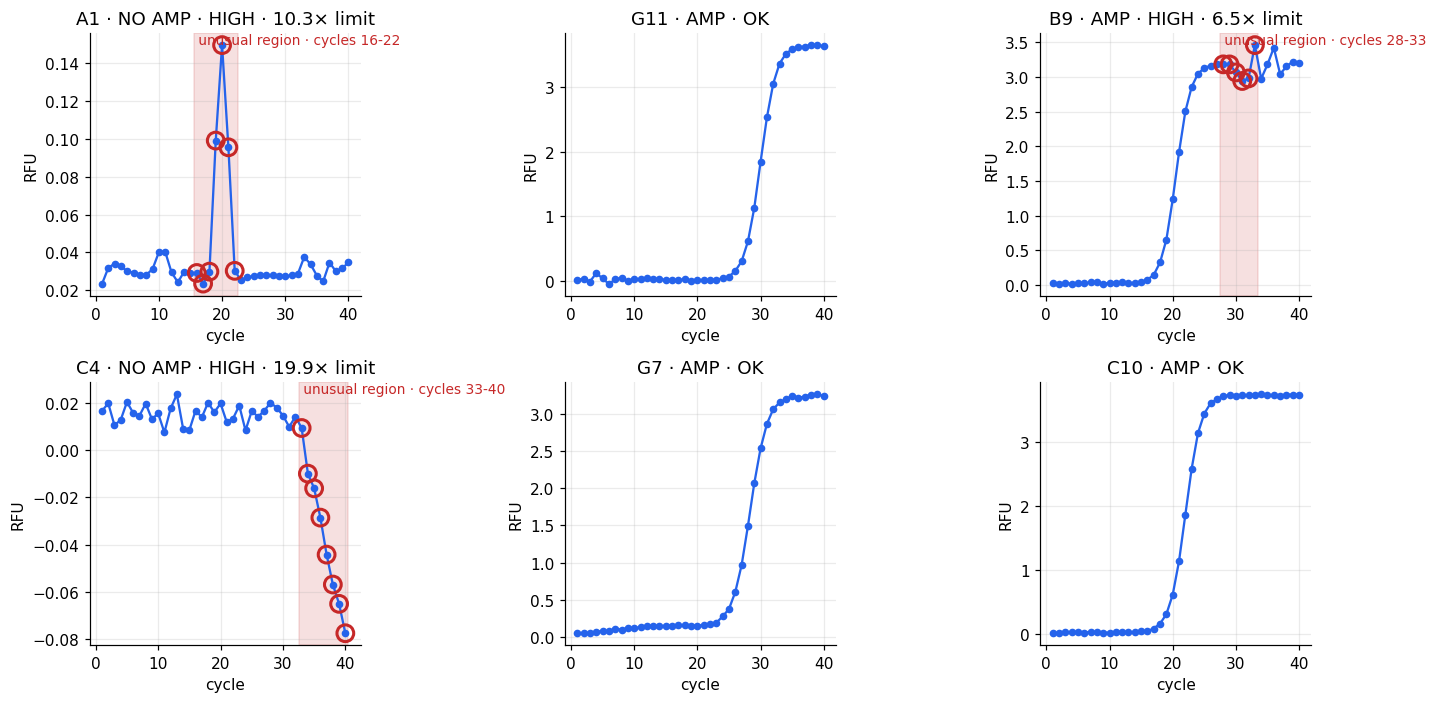

In [24]:
def show_well(well, ax=None):
    i = plate.index[plate.well == well][0]
    res_i, _, extras = pipe.predict(plate.iloc[[i]])
    r = res_i.iloc[0]; flagged = bool(r["anomaly"])
    hot, r0, r1 = flagged_region(extras["cycle_ratio"][0], (int(r["span_start"]), int(r["span_end"])), flagged)
    y = plate.loc[i, CYCLE_COLS].to_numpy(float)
    ax = ax or plt.gca()
    ax.plot(range(1, 41), y, "-o", ms=4, color=BLUE, zorder=3)
    if flagged:
        ax.axvspan(r0 - .5, r1 + .5, color=RED, alpha=.14, zorder=1)
        ax.scatter(hot, y[hot - 1], s=120, facecolors="none", edgecolors=RED, linewidths=2, zorder=4)
        ax.text(r0 - .5, ax.get_ylim()[1], f" unusual region · cycles {r0}-{r1}", color=RED, va="top", fontsize=9)
    ax.set_title(f"{well} · {r['call']} · {r['review_flag']}" + (f" · {r['anomaly_score']/extras['flag_cut']:.1f}× limit" if flagged else ""))
    ax.set_xlabel("cycle"); ax.set_ylabel("RFU")

fig, ax = plt.subplots(2, 3, figsize=(13, 6.5))
for a, w in zip(ax.ravel(), ["A1", "G11", "B9", "C4", "G7", "C10"]): show_well(w, a)
plt.tight_layout(); plt.show()

What each well is (artifacts were injected into this demo plate, so we know the truth):
**A1** a bump on a negative · **G11** an early-noise burst on a positive · **B9** late-plateau noise on a positive ·
**C4** a plateau droop on a negative · **G7** a baseline drift on a positive · **C10** a clean positive with **no** highlight.

## 8. Whole-plate inference and the review tiers

`pipe.predict()` does all of the above for every well, plus the RandomForest amplification call, and assigns a tier:

| Tier | Rule (S relative to the review limit) |
|---|---|
| `HIGH` | S / limit > 2.0 (= 3× the calibrated cut) |
| `REVIEW` | S / limit > 1.0 |
| `BORDERLINE` | not flagged, but the amplification call is uncertain (35–65% confidence) |
| `OK` | otherwise |

In [25]:
print(inspect.getsource(QPCRPipelineV2.predict))

    def predict(self, df):
        """Returns (results, reconstructions, extras). extras carries per-cycle
        arrays the curve viewer needs (hot cycles, ratios)."""
        if self.ae is None or self.clf is None:
            raise RuntimeError("Call fit() before predict().")
        sc = self.ae.score(df)
        X = curve_features(df).to_numpy()
        amp_pred = self.clf.predict(X)
        proba = self.clf.predict_proba(X)[:, 1]
        crossed = (df[CYCLE_COLS].to_numpy(dtype=np.float64) > CLINICAL_THRESHOLD).any(axis=1)

        review_cut = self.ae.flag_cut * REVIEW_MULT
        flagged = sc["S"] > review_cut
        # materiality gate: an amplifying well is only worth a review if it departs from its own
        # fitted S-curve by a visible share of the curve height (small offsets/bumps don't change the result)
        Y = df[CYCLE_COLS].to_numpy(dtype=np.float64)
        for i in np.where(flagged & (amp_pred == 1))[0]:
            height = max(np.median(Y[i, -5:]) - np.med

In [26]:
results, recon, extras = pipe.predict(plate)
results["severity"] = results["anomaly_score"] / extras["flag_cut"]      # 1.0 = exactly at the review limit
print(results["review_flag"].value_counts().to_string(), "\n")
results[results.review_flag.isin(["HIGH", "REVIEW"])] \
    .sort_values("severity", ascending=False)[["well", "call", "confidence", "review_flag", "worst_region", "severity"]] \
    .head(10).round(2)

review_flag
OK        85
HIGH      10
REVIEW     1 



,well,call,confidence,review_flag,worst_region,severity
68,F9,NO AMP,0.00,HIGH,10,47.61
26,C3,NO AMP,0.00,HIGH,7,34.16
52,E5,NO AMP,0.00,HIGH,38,25.58
27,C4,NO AMP,0.00,HIGH,36–40,19.88
0,A1,NO AMP,0.01,HIGH,19,10.29
58,E11,NO AMP,0.01,HIGH,30,10.01
20,B9,AMP,1.00,HIGH,30,6.53
77,G6,NO AMP,0.01,HIGH,19,6.40
5,A6,AMP,1.00,HIGH,33,3.48
74,G3,NO AMP,0.01,HIGH,24–28,3.36


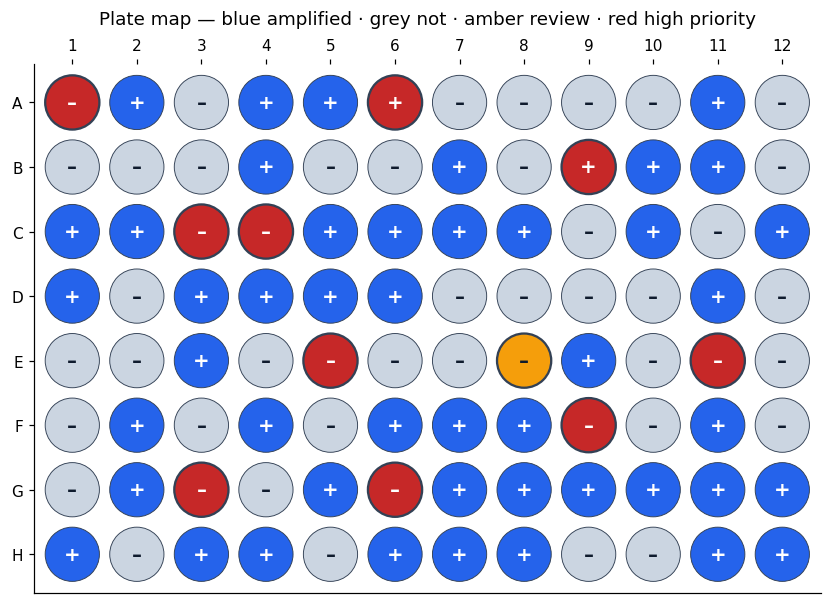

In [27]:
TIER = {"HIGH": RED, "REVIEW": AMBER, "BORDERLINE": "#FDE68A"}
fig, ax = plt.subplots(figsize=(8.5, 5.6))
for _, r in results.iterrows():
    x, y = int(r["col"]), "ABCDEFGH".index(r["row"])
    amp = r["call"] == "AMP"
    ax.add_patch(Circle((x, y), .42, fc=TIER.get(r["review_flag"], BLUE if amp else "#CBD5E1"), ec="#334155", lw=1.5 if r["review_flag"] in ("HIGH", "REVIEW") else .6))
    ax.text(x, y, "+" if amp else "–", ha="center", va="center", fontweight="bold",
            color="white" if (amp and r["review_flag"] == "OK") or r["review_flag"] == "HIGH" else "#0F1B2D", fontsize=13)
ax.set_xlim(.4, 12.6); ax.set_ylim(7.6, -.6); ax.set_aspect("equal"); ax.grid(False)
ax.set_xticks(range(1, 13)); ax.set_yticks(range(8)); ax.set_yticklabels(list("ABCDEFGH")); ax.xaxis.tick_top()
ax.set_title("Plate map — blue amplified · grey not · amber review · red high priority", pad=26)
plt.tight_layout(); plt.show()

## 9. Why the review limit is 1.5×

The flag cut is the 95th percentile of the worst-unit ratio on clean calibration wells, so by construction about 5% of clean wells exceed it.
Testing on wells the model **never saw** (train on 85%, score the held-out 15% clean + artifact-injected copies) showed the false flags are all marginal:

| Review limit | False flags, negatives | False flags, positives | Artifacts caught |
|---|---|---|---|
| 1.0× (the raw cut) | 8.1% | 14.8% | 95.6% |
| **1.5× (used)** | **0.7%** | **2.6%** | **92.4%** |
| 2.0× | 0.0% | 0.0% | 89.6% |
| 3.0× | 0.0% | 0.0% | 84.1% |

Every false flag was between 1.0× and 1.8× the cut and mostly at the steep takeoff (cycles 20–25), while real artifacts have a median of about 11×.
So raising the limit removes the noise at little cost. Change `REVIEW_MULT` in `qpcr_v2.py` to move along this trade-off.

**Retraining.** `python train_model.py` rebuilds `qpcr_model.pkl` from `train_normal.csv` (about 3 minutes on a laptop CPU).